<center><a href="https://github.com/CyConProject?tab=repositories"><img src="https://github.com/CyConProject/Lab/blob/main/Figures/CyCon.png?raw=true" alt="CyCon logo" width="80"></a></center>

## Module 4-4 Lab: Keras Implementation of Convolutional Networks
### Concrete Crack Classification with SDNET2018

An infrastructure inspection can produce hundreds of concrete-surface photographs. Can a CNN help flag image patches containing a visible crack for an engineer to review? You will train two small CNNs on real images of **bridge decks, pavements, and walls**, then examine both their predictions and their mistakes.

This lab follows **4-2 Shallow vs. Deep Architectures** and **4-3 Convolutional Networks Explanation**. It builds on the image-classification workflow from Module 3, using the same eight-section format, while focusing on convolution, pooling, feature maps, and architecture comparison.

### Objectives

1. Load construction-related imagery and explain the crack/no-crack label mapping.
2. Prepare RGB image tensors and separate training, validation, and testing.
3. Build and train CNNs with one and two convolution–pooling blocks in Keras.
4. Explain filters, shared weights, ReLU, pooling, flattening, and sigmoid output.
5. Compare validation performance, parameter counts, and training time.
6. Visualize learned feature maps and evaluate crack recall and false alarms.
7. Describe how image screening could support an inspection workflow and where engineering judgment is still needed.

**Time:** approximately 90–120 minutes; download and training time vary. **Runtime:** Google Colab with a GPU is recommended; a small CPU run is also possible. **Prerequisites:** basic Python, Keras `Sequential`, and binary classification from Module 3.

**How to work:** Try each `# To Do` cell before expanding its solution. The following reference cell supplies the complete implementation, so the notebook also runs from top to bottom. If you change a reference cell, rerun its dependent cells. Add your observations in the response cells.

## 1. Recap: Why CNNs for Construction Images?

A dense network flattens an image before learning. A CNN first scans local neighborhoods with **learned filters**. Shared filter weights let it look for the same pattern at different image positions. Early features may respond to contrast changes or textures; later layers combine earlier features. The filters are learned from examples, not predefined crack detectors.

| Component | What it does | Connection to this lab |
|---|---|---|
| `Conv2D` | Applies learned filters to local pixel neighborhoods | Learns patterns that may distinguish cracks from surface texture |
| ReLU / LeakyReLU | ReLU zeros negative inputs; LeakyReLU retains a small negative slope | This lab uses LeakyReLU to reduce the risk of inactive hidden units |
| `MaxPooling2D` | Keeps each neighborhood's largest activation | Reduces spatial resolution and computation; may also remove fine detail |
| `Flatten` / `GlobalAveragePooling2D` | Flatten retains every value; global pooling averages each channel | This lab uses global pooling to make the classification head smaller |
| `Dense(1, activation="sigmoid")` | Produces a score between 0 and 1 | Gives the model's score for the crack class |

Our tensors have shape **(batch, height, width, channels)**. We use RGB images, so channels = 3. For two classes, one sigmoid output with **binary cross-entropy** is sufficient; one-hot labels and a 10-class softmax are unnecessary.

**Construction application:** flagged patches could help prioritize review of inspection imagery or organize a defect-image archive. This task is **patch classification**: it does not draw a crack boundary, measure width, identify a cause, or determine load capacity. Detecting an entire crack's location would require an object-detection or segmentation workflow.

## 2. Part I – Setup and Data Loading

We use the [SDNET2018 Kaggle dataset](https://www.kaggle.com/datasets/aniruddhsharma/structural-defects-network-concrete-crack-images/data) supplied for this course. The original dataset contains over 56,000 cracked and non-cracked concrete image patches from bridge decks, walls, and pavements, including challenging surface textures and obstructions [1].

The Kaggle download can use descriptive folders such as **`Decks/Cracked`** and **`Decks/Non-cracked`**, with equivalent pairs under `Pavements` and `Walls`. Other SDNET2018 distributions use short folder names such as `CD` and `UD`. The loader below recognizes both layouts, including nested directories and differences in capitalization, spaces, underscores, or hyphens.

| Descriptive folder | Short name | Surface | Label |
|---|---|---|---:|
| `Decks/Cracked` | `CD` | Deck | 1 |
| `Decks/Non-cracked` | `UD` | Deck | 0 |
| `Pavements/Cracked` | `CP` | Pavement | 1 |
| `Pavements/Non-cracked` | `UP` | Pavement | 0 |
| `Walls/Cracked` | `CW` | Wall | 1 |
| `Walls/Non-cracked` | `UW` | Wall | 0 |

Label **1** means cracked; label **0** means uncracked. We combine the folders into a binary task while retaining surface information. The `folder` column uses the short group codes for either layout, so subsequent sampling and splitting code stays the same. `kagglehub` supplies the download directory automatically; no instructor-specific computer path is used.

**Before running:** enable a GPU in Colab if available. The installation cell installs only missing packages. If the runtime asks for a restart, restart and run from the beginning. The dataset download may take several minutes and requires internet access and sufficient disk space. If Kaggle requests authentication, follow its prompts without putting credentials in this notebook. Alternatively, extract the dataset yourself and set `DATA_DIR` below. The classroom subset reduces training work, but the first download still retrieves the dataset.

In [ ]:
# Install only packages that are absent. Colab usually already has TensorFlow.
import importlib.util
import subprocess
import sys
packages = {"tensorflow": "tensorflow", "kagglehub": "kagglehub",
            "sklearn": "scikit-learn", "pandas": "pandas",
            "matplotlib": "matplotlib", "PIL": "Pillow"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

In [ ]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras import Sequential, Input, Model
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Flatten, Dense,
                                    Rescaling, LayerNormalization, LeakyReLU, Dropout,
                                    GlobalAveragePooling2D, RandomFlip)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score)

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


In [ ]:
# Set an extracted dataset directory here to skip downloading.
# Example: DATA_DIR = "/content/SDNET2018"
DATA_DIR = None
if DATA_DIR is None:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download(
        "aniruddhsharma/structural-defects-network-concrete-crack-images"
    )
root = Path(DATA_DIR).expanduser()
if not root.is_dir():
    raise FileNotFoundError(f"Dataset directory does not exist: {root}")
print("Path to dataset files:", root)

100%|██████████| 506M/506M [00:25<00:00, 21.1MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/aniruddhsharma/structural-defects-network-concrete-crack-images/versions/1


> **Exercise 1:** Find the six SDNET folders, count images in each, and display a labeled example from each folder.

In [ ]:
# To Do
# Find folders using their names, not a fixed absolute path.
# Build columns: path, folder, surface, label.
# Print counts and display six examples.

<details><summary>Solution to Exercise 1 (click to expand)</summary>

Inspect directory names first, because dataset distributors may organize the same labels differently:

```python
for folder in sorted(root.rglob("*")):
    if folder.is_dir():
        print(folder.relative_to(root))
```

`Decks/Cracked` maps to deck, label 1; `Decks/Non-cracked` maps to deck, label 0. Apply the same rule for pavements and walls. Short names such as `CD` and `UD` provide the same mapping. Match class names exactly after normalization, so `Non-cracked` is not accidentally assigned the cracked label.

Run the reference implementation below to build `image_table`, print group counts, and display examples.

</details>

CD -> /root/.cache/kagglehub/datasets/aniruddhsharma/structural-defects-network-concrete-crack-images/versions/1/Decks/Cracked
UD -> /root/.cache/kagglehub/datasets/aniruddhsharma/structural-defects-network-concrete-crack-images/versions/1/Decks/Non-cracked
CP -> /root/.cache/kagglehub/datasets/aniruddhsharma/structural-defects-network-concrete-crack-images/versions/1/Pavements/Cracked
UP -> /root/.cache/kagglehub/datasets/aniruddhsharma/structural-defects-network-concrete-crack-images/versions/1/Pavements/Non-cracked
CW -> /root/.cache/kagglehub/datasets/aniruddhsharma/structural-defects-network-concrete-crack-images/versions/1/Walls/Cracked
UW -> /root/.cache/kagglehub/datasets/aniruddhsharma/structural-defects-network-concrete-crack-images/versions/1/Walls/Non-cracked
folder  surface   label
CD      Deck      1         2025
CP      Pavement  1         2608
CW      Wall      1         3851
UD      Deck      0        11595
UP      Pavement  0        21726
UW      Wall      0        14

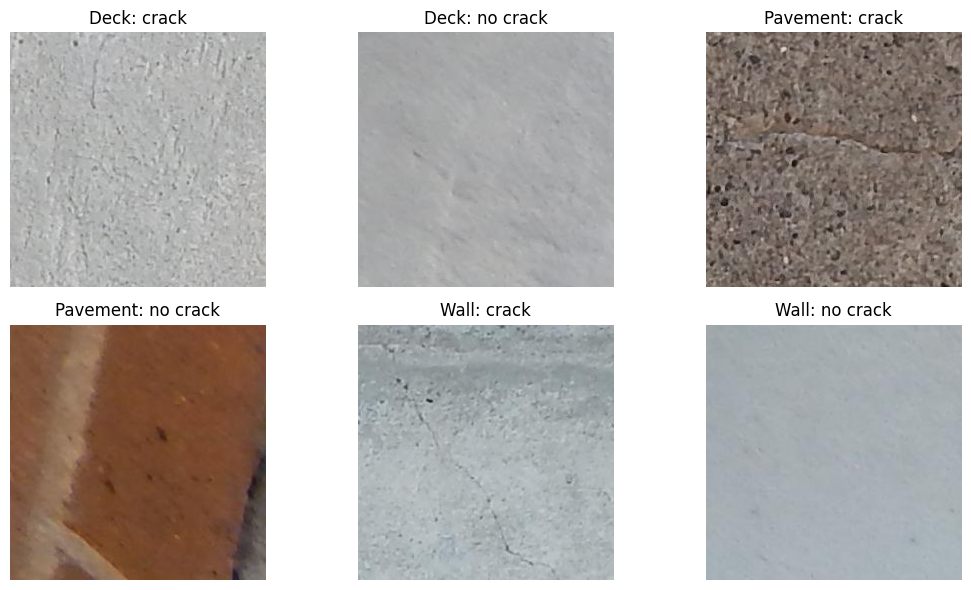

In [ ]:
# Reference implementation: support both common SDNET2018 layouts.
FOLDER_MAP = {"cd": ("Deck", 1), "ud": ("Deck", 0),
              "cp": ("Pavement", 1), "up": ("Pavement", 0),
              "cw": ("Wall", 1), "uw": ("Wall", 0)}
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp"}

def normalize_folder_name(name):
    # Treat Non-cracked, Non_Cracked, and Non cracked as the same name.
    return "".join(character for character in name.lower() if character.isalnum())

def discover_sdnet_images(dataset_root):
    dataset_root = Path(dataset_root).expanduser()
    if not dataset_root.is_dir():
        raise FileNotFoundError(f"Dataset directory does not exist: {dataset_root}")
    surface_names = {"deck": "d", "decks": "d",
                     "pavement": "p", "pavements": "p",
                     "wall": "w", "walls": "w"}
    class_names = {"cracked": "c", "crack": "c",
                   "noncracked": "u", "uncracked": "u", "nocrack": "u"}
    rows, recognized = [], []
    for folder in sorted([dataset_root, *dataset_root.rglob("*")]):
        if not folder.is_dir():
            continue
        name = normalize_folder_name(folder.name)
        key = name if name in FOLDER_MAP else None
        if key is None and name in class_names:
            # Use an exact class-name match: 'noncracked' must never become 'cracked'.
            # Search enclosing folders to allow an extra wrapper directory.
            ancestor = folder.parent
            while ancestor == dataset_root or dataset_root in ancestor.parents:
                surface_code = surface_names.get(normalize_folder_name(ancestor.name))
                if surface_code is not None:
                    key = class_names[name] + surface_code
                    break
                if ancestor == dataset_root:
                    break
                ancestor = ancestor.parent
        if key is None:
            continue
        recognized.append((key.upper(), folder))
        surface, label = FOLDER_MAP[key]
        for path in sorted(folder.rglob("*")):
            if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES:
                rows.append({"path": str(path.resolve()), "folder": key.upper(),
                             "surface": surface, "label": label})
    if not rows:
        visible = [str(folder.relative_to(dataset_root))
                   for folder in sorted(dataset_root.rglob("*")) if folder.is_dir()][:20]
        raise FileNotFoundError(
            "No SDNET images found. Expected CD/UD/CP/UP/CW/UW folders, or "
            "Decks/Pavements/Walls containing Cracked and Non-cracked folders. "
            "DATA_DIR must point to extracted files, not a ZIP archive. "
            f"First subdirectories found: {visible}")
    table = pd.DataFrame(rows).drop_duplicates("path").reset_index(drop=True)
    present = set(table["folder"].str.lower())
    missing = set(FOLDER_MAP) - present
    if missing:
        raise FileNotFoundError(
            f"No supported images found for these SDNET groups: {sorted(missing)}. "
            "Check that all three surfaces and both classes were downloaded/extracted.")
    for key, folder in recognized:
        print(key, "->", folder)
    return table

image_table = discover_sdnet_images(root)
print(image_table.groupby(["folder", "surface", "label"]).size().rename("images").to_string())
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, key in zip(axes.ravel(), FOLDER_MAP):
    row = image_table[image_table.folder == key.upper()].iloc[0]
    with Image.open(row.path) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"{row.surface}: {'crack' if row.label else 'no crack'}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 3. Part II – Split and Prepare the Images

Select up to **1,000 images from each folder** (at most 6,000 total). Use the same number from each folder, limited by the smallest group. This balances both the binary label and the surface type. Check that selected files can be read; any unreadable files are reported and excluded before splitting.

Split into **60% training / 20% validation / 20% test**, stratifying by folder so each partition includes all six groups. Training updates weights; validation guides architecture selection; testing reports the selected model's performance after the choices are fixed.

These are **random patch splits**. Disjoint file paths do not guarantee independent source photographs. Neighboring patches from one photograph or structure can look similar. This classroom experiment is not an estimate of performance at a completely new site. A stronger study should group by original photograph or structure using verified metadata; do not guess those groups from filenames.

Resize to **128 × 128** with three RGB channels for a manageable run. Resizing can erase thin cracks. We retain pixel values on the 0–255 scale here; a `Rescaling` layer inside each model divides by 255 exactly once.

> **Exercise 2:** Create the classroom subset and stratified partitions. Verify that no file path appears in more than one partition.

In [ ]:
# To Do
# Sample the same number from each folder with SEED.
# Split twice with stratify=frame["folder"].
# Print folder counts by partition and check path overlap.

<details><summary>Solution to Exercise 2 (click to expand)</summary>

```python
train_df, other_df = train_test_split(
    subset, test_size=0.40, random_state=SEED, stratify=subset["folder"])
val_df, test_df = train_test_split(
    other_df, test_size=0.50, random_state=SEED, stratify=other_df["folder"])
```

Run the reference implementation below to continue.

</details>

In [ ]:
# Reference implementation
IMAGES_PER_FOLDER = 1000  # 6,000 images total; use 300 for a shorter exploratory run.
rng = np.random.default_rng(SEED)
n_per_folder = min(IMAGES_PER_FOLDER, int(image_table.groupby("folder").size().min()))
if n_per_folder < 30:
    raise ValueError("Too few images in at least one folder; check the dataset extraction.")
pieces = []
for _, group in image_table.groupby("folder", sort=True):
    indices = rng.choice(group.index.to_numpy(), size=n_per_folder, replace=False)
    pieces.append(image_table.loc[indices])
subset = pd.concat(pieces, ignore_index=True)
valid, unreadable = [], []
for row in subset.itertuples():
    try:
        with Image.open(row.path) as image:
            image.convert("RGB").load()
        valid.append(True)
    except (OSError, ValueError) as exc:
        valid.append(False)
        unreadable.append((row.path, str(exc)))
subset = subset.loc[valid].reset_index(drop=True)
print("Unreadable selected files excluded:", len(unreadable))
for item in unreadable[:5]:
    print(item)
if any((subset.folder == key.upper()).sum() < 30 for key in FOLDER_MAP):
    raise ValueError("Insufficient readable images in a folder.")
train_df, other_df = train_test_split(
    subset, test_size=0.40, random_state=SEED, stratify=subset["folder"])
val_df, test_df = train_test_split(
    other_df, test_size=0.50, random_state=SEED, stratify=other_df["folder"])
train_df, val_df, test_df = [frame.reset_index(drop=True)
                             for frame in (train_df, val_df, test_df)]
parts = {"Train": train_df, "Validation": val_df, "Test": test_df}
counts = pd.DataFrame({name: frame.folder.value_counts() for name, frame in parts.items()}).sort_index()
print(counts.to_string())
print("Total images:", {name: len(frame) for name, frame in parts.items()})
assert not (set(train_df.path) & set(val_df.path) or
            set(train_df.path) & set(test_df.path) or
            set(val_df.path) & set(test_df.path))

Unreadable selected files excluded: 0
        Train  Validation  Test
folder                         
CD        600         200   200
CP        600         200   200
CW        600         200   200
UD        600         200   200
UP        600         200   200
UW        600         200   200
Total images: {'Train': 3600, 'Validation': 1200, 'Test': 1200}


In [ ]:
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32

def decode_image(path, label):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image.set_shape((None, None, 3))
    image = tf.image.resize(image, IMAGE_SIZE)
    return image, tf.reshape(tf.cast(label, tf.float32), (1,))

def make_dataset(frame, training=False, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices(
        (frame.path.to_numpy(dtype=str), frame.label.to_numpy(dtype=np.float32)))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)  # Unshuffled: predictions match test_df row order.
images_batch, labels_batch = next(iter(train_ds))
print("Images:", images_batch.shape, "Labels:", labels_batch.shape)
print("Pixel range before model rescaling:", float(tf.reduce_min(images_batch)),
      float(tf.reduce_max(images_batch)))
assert images_batch.shape[1:] == (*IMAGE_SIZE, 3)
assert labels_batch.shape[-1] == 1

Images: (32, 128, 128, 3) Labels: (32, 1)
Pixel range before model rescaling: 0.0 251.75


## 4. Part III – Build a CNN with One Convolution–Pooling Block

Start with **16 filters**, each with a **5 × 5** kernel, stride 1, and `padding="same"`. LeakyReLU keeps a small negative slope (0.1), so a hidden unit can still receive gradients when its input is negative. A 2 × 2 max-pooling layer halves height and width.

The original flattened head contained over half a million parameters and could memorize this small dataset. Here, **global average pooling** averages each feature map over its spatial dimensions, producing one value per channel. This provides a much smaller classification head. It is different from local max pooling: global pooling summarizes the entire map. A tradeoff is that precise feature positions are discarded.

| Stage | Output shape per image |
|---|---|
| RGB input and per-patch normalization | 128 × 128 × 3 |
| 16 convolution filters and LeakyReLU | 128 × 128 × 16 |
| 2 × 2 max pooling | 64 × 64 × 16 |
| Global average pooling | 16 |
| Dense hidden layer and LeakyReLU | 24 |
| Sigmoid output | 1 |

A convolution layer with bias has **(kernel height × kernel width × input channels + 1) × filters** parameters. The first layer has `(5 × 5 × 3 + 1) × 16 = 1,216`. The full one-block CNN has **1,649** trainable parameters.

**Training settings:** images are scaled to 0–1, normalized per patch, and randomly flipped during training only. Flips model the absence of a preferred crack direction; validation and test images are unchanged. He initialization and LeakyReLU support optimization; dropout reduces reliance on individual hidden features. Each candidate receives a fresh Adam optimizer with learning rate 0.001 and gradient clipping. The dataset is balanced, so class weights are unnecessary.


> **Exercise 3:** Build the one-block CNN with per-patch normalization, LeakyReLU, and global average pooling. Compile with Adam (learning rate 0.001), binary cross-entropy, accuracy, and AUC. Confirm that the first convolution has 1,216 parameters.

In [ ]:
# To Do
# Write build_cnn(blocks=1) using the shape table.
# Include Input, Rescaling, Conv2D, MaxPooling2D, GlobalAveragePooling2D, and Dense.
# Add an optional second block for Part VI.

<details><summary>Solution to Exercise 3 (click to expand)</summary>

Use the reference `build_cnn()` below. The first block is:

```python
Input(shape=(*IMAGE_SIZE, 3))
Rescaling(1.0 / 255)
LayerNormalization(axis=[1, 2, 3], center=False, scale=False, epsilon=1e-4)
RandomFlip("horizontal_and_vertical", seed=SEED)
Conv2D(16, 5, padding="same", kernel_initializer="he_normal")
LeakyReLU(negative_slope=0.1)
MaxPooling2D(2)
```

Add a GlobalAveragePooling2D layer, a 24-unit dense hidden layer with LeakyReLU, dropout (0.25), and a sigmoid output. Create a new Adam optimizer for each model, with learning rate 0.001 and `clipnorm=1.0`.

</details>

In [ ]:
# Reference implementation: small CNNs with a stable classification head.
def build_cnn(blocks=1):
    if blocks not in (1, 2):
        raise ValueError("Use one or two convolution–pooling blocks.")
    # Fix initialization before building each candidate, not after creating its weights.
    tf.keras.utils.set_random_seed(SEED)
    layers = [Input(shape=(*IMAGE_SIZE, 3)), Rescaling(1.0 / 255, name="scale"),
              # Normalize each patch's intensity/contrast; no dataset statistics are fitted.
              LayerNormalization(axis=[1, 2, 3], center=False, scale=False,
                                 epsilon=1e-4, name="patch_normalization"),
              RandomFlip("horizontal_and_vertical", seed=SEED, name="augmentation"),
              Conv2D(16, 5, padding="same", kernel_initializer="he_normal", name="conv_1"),
              LeakyReLU(negative_slope=0.1, name="activation_1"),
              MaxPooling2D(2, name="pool_1")]
    if blocks == 2:
        layers += [Conv2D(32, 3, padding="same", kernel_initializer="he_normal", name="conv_2"),
                   LeakyReLU(negative_slope=0.1, name="activation_2"),
                   MaxPooling2D(2, name="pool_2")]
    layers += [GlobalAveragePooling2D(name="global_pool"),
               Dense(24, kernel_initializer="he_normal", name="head"),
               LeakyReLU(negative_slope=0.1, name="head_activation"),
               Dropout(0.25, name="head_dropout"),
               Dense(1, activation="sigmoid", name="crack_score")]
    model = Sequential(layers, name=f"cnn_{blocks}_block")
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001, clipnorm=1.0),
                  loss="binary_crossentropy", metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return model

one_block_model = build_cnn(blocks=1)
one_block_model.summary()
print("First convolution parameters:", one_block_model.get_layer("conv_1").count_params())
# Parameter comparison only; the dense baseline is not trained.
dense_baseline = Sequential([Input(shape=(*IMAGE_SIZE, 3)), Rescaling(1.0 / 255),
                             Flatten(), Dense(24, activation="relu"),
                             Dense(1, activation="sigmoid")])
print("Dense baseline parameters (not trained):", dense_baseline.count_params())
print("One-block CNN parameters:", one_block_model.count_params())


Model: "cnn_1_block"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ scale (Rescaling)               │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ patch_normalization             │ (None, 128, 128, 3)    │             0 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (RandomFlip)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 128, 128, 16)   │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (LeakyReLU)        │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_pool                     │ (None, 16)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head (Dense)                    │ (None, 24)             │           408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_activation (LeakyReLU)     │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ crack_score (Dense)             │ (None, 1)              │            25 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,649 (6.44 KB)

 Trainable params: 1,649 (6.44 KB)

 Non-trainable params: 0 (0.00 B)

First convolution parameters: 1216
Dense baseline parameters (not trained): 1179697
One-block CNN parameters: 1649


## 5. Part IV – Train and Read Validation Results

Train for up to **30 epochs** with Adam at learning rate 0.001. A loss near **0.693** and accuracy near **50%** on a balanced binary dataset indicate little useful learning. A model that predicts every patch as cracked can obtain 100% crack recall while missing the entire uncracked class.

`ReduceLROnPlateau` halves the learning rate after three epochs without meaningful improvement. `EarlyStopping` monitors from the first epoch, allows ten epochs without improvement, and restores the lowest-validation-loss weights. The restored model need not be the last epoch.

Each candidate prints validation prediction counts, score quantiles, ROC-AUC, balanced accuracy, and recall for **both classes**. For this lab, a candidate passes a basic learning check only if both recalls are at least 0.20, balanced accuracy is at least 0.55, and ROC-AUC is at least 0.55. These are modest classroom checks, not deployment criteria. The gate blocks a final report if neither candidate learns usefully.

Lower training loss alongside rising validation loss suggests overfitting. Persistently poor training and validation results suggest an optimization problem, weak features, difficult data, or label issues. Inspect the curves and class-specific diagnostics rather than calling a completed run a successful model.


Epoch 1/30
113/113 - 57s - 505ms/step - accuracy: 0.5094 - auc: 0.5097 - loss: 0.7175 - val_accuracy: 0.5350 - val_auc: 0.5657 - val_loss: 0.6890 - learning_rate: 0.0010
Epoch 2/30
113/113 - 51s - 454ms/step - accuracy: 0.5181 - auc: 0.5309 - loss: 0.6982 - val_accuracy: 0.5342 - val_auc: 0.5578 - val_loss: 0.6867 - learning_rate: 0.0010
Epoch 3/30
113/113 - 81s - 718ms/step - accuracy: 0.5358 - auc: 0.5515 - loss: 0.6898 - val_accuracy: 0.5800 - val_auc: 0.6181 - val_loss: 0.6823 - learning_rate: 0.0010
Epoch 4/30
113/113 - 49s - 436ms/step - accuracy: 0.5436 - auc: 0.5601 - loss: 0.6867 - val_accuracy: 0.5917 - val_auc: 0.6291 - val_loss: 0.6800 - learning_rate: 0.0010
Epoch 5/30
113/113 - 49s - 434ms/step - accuracy: 0.5600 - auc: 0.5779 - loss: 0.6832 - val_accuracy: 0.5558 - val_auc: 0.6370 - val_loss: 0.6787 - learning_rate: 0.0010
Epoch 6/30
113/113 - 54s - 477ms/step - accuracy: 0.5483 - auc: 0.5734 - loss: 0.6846 - val_accuracy: 0.5692 - val_auc: 0.6347 - val_loss: 0.6748 - le

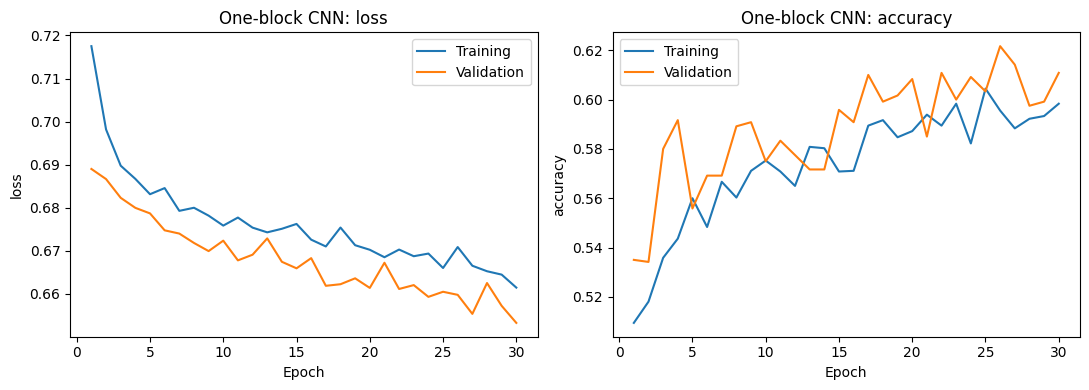

In [ ]:
MAX_EPOCHS = 30

def train_candidate(model, batch_size=BATCH_SIZE):
    tf.keras.utils.set_random_seed(SEED)
    training = make_dataset(train_df, training=True, batch_size=batch_size)
    validation = make_dataset(val_df, batch_size=batch_size)
    stopper = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True)
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1)
    start = perf_counter()
    history = model.fit(training, validation_data=validation,
                        epochs=MAX_EPOCHS, callbacks=[reduce_lr, stopper,
                        tf.keras.callbacks.TerminateOnNaN()], shuffle=False, verbose=2)
    seconds = perf_counter() - start
    scores = model.evaluate(validation, return_dict=True, verbose=0)
    probabilities = model.predict(validation, verbose=0).ravel()
    prediction = (probabilities >= 0.50).astype(int)
    actual = val_df.label.to_numpy(dtype=int)
    cm_val = confusion_matrix(actual, prediction, labels=[0, 1])
    tn, fp, fn, tp = cm_val.ravel()
    no_crack_recall = tn / max(tn + fp, 1)
    crack_recall = tp / max(tp + fn, 1)
    balanced_acc = balanced_accuracy_score(actual, prediction)
    auc = roc_auc_score(actual, probabilities)
    learned_both = bool(no_crack_recall >= 0.20 and crack_recall >= 0.20
                        and balanced_acc >= 0.55 and auc >= 0.55)
    summary = {"model": model.name, "parameters": model.count_params(),
               "epochs_run": len(history.history["loss"]),
               "seconds": seconds, "batch_size": batch_size,
               "validation_loss": scores["loss"],
               "validation_accuracy": scores["accuracy"],
               "validation_balanced_accuracy": balanced_acc,
               "validation_auc": auc, "no_crack_recall": no_crack_recall,
               "crack_recall": crack_recall, "learned_both_classes": learned_both}
    print("Validation predictions (0=no crack, 1=crack):",
          np.bincount(prediction, minlength=2))
    print("Validation score range:", np.round(np.quantile(probabilities, [0, .25, .5, .75, 1]), 3))
    if not learned_both:
        print("Learning check FAILED: this candidate is not yet a useful two-class demonstration.")
    return history, summary

one_history, one_summary = train_candidate(one_block_model)
print(pd.DataFrame([one_summary]).round(3).to_string(index=False))

def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    epochs = np.arange(1, len(history.history["loss"]) + 1)
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs, history.history[metric], label="Training")
        ax.plot(epochs, history.history["val_" + metric], label="Validation")
        ax.set(xlabel="Epoch", ylabel=metric, title=f"{title}: {metric}")
        ax.legend()
    plt.tight_layout()
    plt.show()

plot_history(one_history, "One-block CNN")

> **Exercise 4:** Find the epoch with the lowest validation loss. Explain whether the curves suggest overfitting, and why the restored model need not match the last epoch.

In [ ]:
# To Do
# Use np.argmin on val_loss and add 1 to report epoch numbers.
# Compare training and validation accuracy at that epoch.

<details><summary>Solution to Exercise 4 (click to expand)</summary>

```python
best = int(np.argmin(one_history.history["val_loss"]))
print("Best epoch:", best + 1)
print("Training accuracy:", one_history.history["accuracy"][best])
print("Validation accuracy:", one_history.history["val_accuracy"][best])
```

Run the reference implementation below to continue.

</details>

In [ ]:
# Reference implementation
best = int(np.argmin(one_history.history["val_loss"]))
print("Lowest validation-loss epoch:", best + 1)
print("Training / validation accuracy:",
      round(one_history.history["accuracy"][best], 3),
      round(one_history.history["val_accuracy"][best], 3))

Lowest validation-loss epoch: 30
Training / validation accuracy: 0.598 0.611


**Your response:** Describe the curves in two or three sentences.

*Write here.*

## 6. Part V – Inspect Predictions and Learned Feature Maps

Use **validation images** for exploration. At threshold 0.50, a score ≥ 0.50 predicts a crack. A sigmoid score is not automatically a calibrated probability of structural damage.

Feature maps show activations produced by learned filters. Different filters can respond to different textures or contrast patterns. Bright activations do not by themselves prove that the network has localized a crack. Each map below is displayed with its own color scale, so brightness cannot be compared directly between maps.

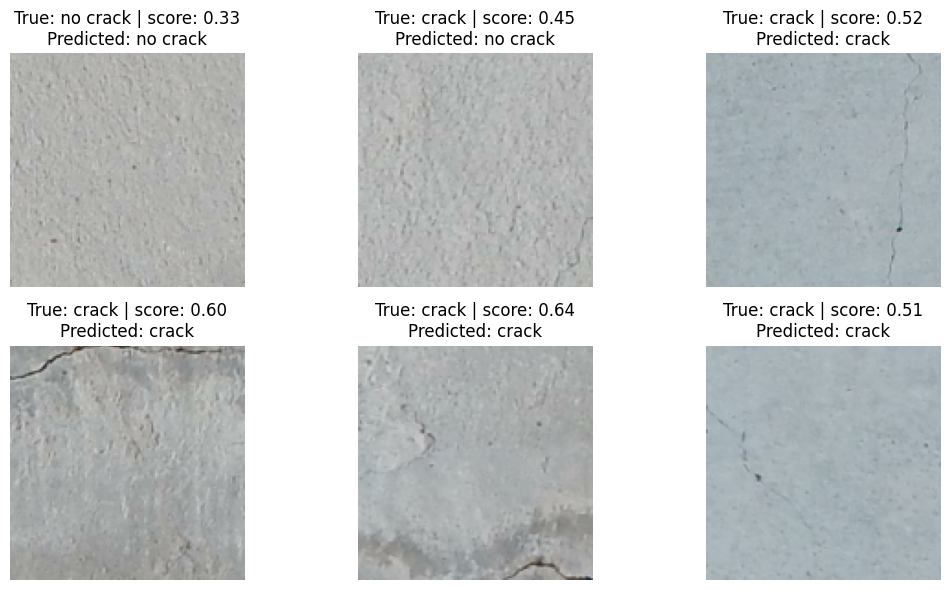

In [ ]:
preview_df = val_df.iloc[:6]
preview_images, preview_labels = next(iter(make_dataset(preview_df)))
preview_scores = one_block_model.predict(preview_images, verbose=0).ravel()
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, image, label, score in zip(axes.ravel(), preview_images, preview_labels, preview_scores):
    ax.imshow(tf.cast(tf.clip_by_value(image, 0, 255), tf.uint8).numpy())
    actual = int(label.numpy()[0])
    ax.set_title(f"True: {'crack' if actual else 'no crack'} | score: {score:.2f}\n"
                 f"Predicted: {'crack' if score >= 0.5 else 'no crack'}")
    ax.axis("off")
plt.tight_layout()
plt.show()

> **Exercise 5:** Display eight feature maps from the first convolution for a cracked validation patch. Identify a response to texture or contrast and explain why this is not a crack segmentation mask.

In [ ]:
# To Do
# Build a Model ending at activation_1 using the trained layers.
# Predict on one validation image and plot channels 0 through 7.

<details><summary>Solution to Exercise 5 (click to expand)</summary>

```python
probe_input = Input(shape=(*IMAGE_SIZE, 3))
x = one_block_model.get_layer("scale")(probe_input)
x = one_block_model.get_layer("patch_normalization")(x)
x = one_block_model.get_layer("augmentation")(x, training=False)
x = one_block_model.get_layer("conv_1")(x)
x = one_block_model.get_layer("activation_1")(x)
feature_viewer = Model(probe_input, x)
# maps = feature_viewer.predict(one_image, verbose=0)[0]
```

Run the reference implementation below to continue.

</details>

First convolution feature-map shape: (128, 128, 16)


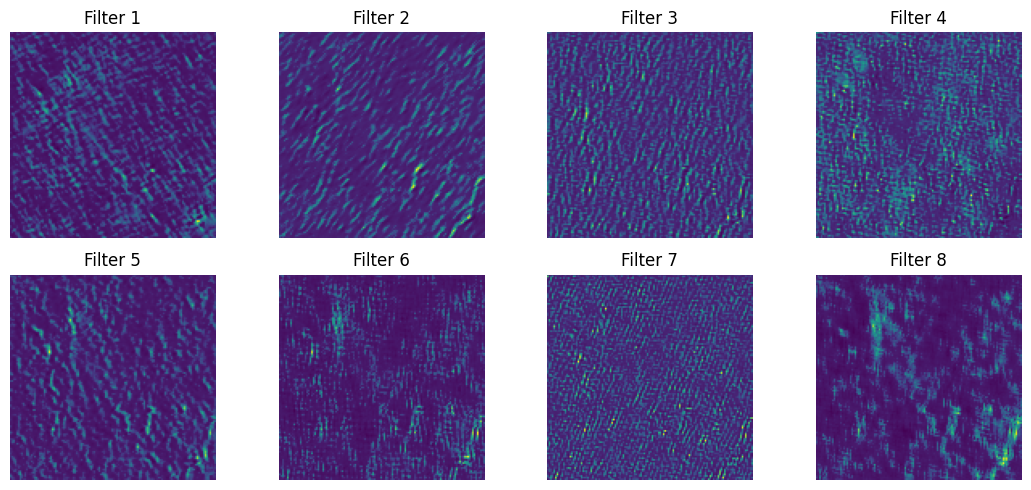

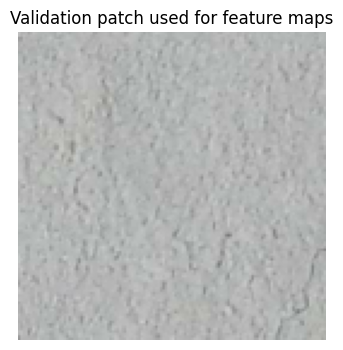

In [ ]:
# Reference implementation
cracked_index = int(np.flatnonzero(val_df.label.to_numpy() == 1)[0])
one_image, _ = next(iter(make_dataset(val_df.iloc[[cracked_index]])))
# Explicit symbolic input avoids Sequential.input issues across Keras versions.
probe_input = Input(shape=(*IMAGE_SIZE, 3))
x = probe_input
for layer in one_block_model.layers:
    x = layer(x)
    if layer.name == "activation_1":
        break
feature_viewer = Model(probe_input, x)
maps = feature_viewer.predict(one_image, verbose=0)[0]
print("First convolution feature-map shape:", maps.shape)
fig, axes = plt.subplots(2, 4, figsize=(11, 5))
for channel, ax in enumerate(axes.ravel()):
    ax.imshow(maps[:, :, channel], cmap="viridis")
    ax.set_title(f"Filter {channel + 1}")
    ax.axis("off")
plt.tight_layout()
plt.show()
plt.figure(figsize=(4, 4))
plt.imshow(tf.cast(tf.clip_by_value(one_image[0], 0, 255), tf.uint8).numpy())
plt.title("Validation patch used for feature maps")
plt.axis("off")
plt.show()

**Your response:** Compare the original patch and two feature maps.

*Write here.*

## 7. Part VI – Mini Project: Compare CNN Architectures

Add a second block: **32 filters**, 3 × 3 kernels, same padding, LeakyReLU, and 2 × 2 max pooling. Its output is **32 × 32 × 32**. Global average pooling converts it into 32 values; the dense hidden layer stays at 24 units.

The two-block CNN has **6,673** trainable parameters. With the compact globally pooled head, adding the second block increases total parameters. In a flattened-head design, additional pooling can instead reduce total parameters by shrinking the large dense head. Check the summaries rather than assuming depth determines model size. More layers do not guarantee better accuracy.

Both candidates use the same partitions, optimizer, maximum epochs, and early-stopping rule. Their stopping epochs may differ, so record epochs and elapsed time. Timing is approximate: runtime load, GPU warm-up, and image reading affect it. A single seeded run is a classroom comparison, not a rigorous architecture benchmark.

> **Exercise 6:** Train the two-block model. Compare validation loss, validation accuracy, parameters, and training time with the one-block model. Explain why adding a block changes the dense-head size.

In [ ]:
# To Do
# Reuse build_cnn(blocks=2) and train_candidate.
# Build a comparison table from the two summaries.
# Do not evaluate test_ds yet.

<details><summary>Solution to Exercise 6 (click to expand)</summary>

```python
two_block_model = build_cnn(blocks=2)
two_history, two_summary = train_candidate(two_block_model)
comparison = pd.DataFrame([one_summary, two_summary])
print(comparison)
```

Run the reference implementation below to continue.

</details>

Model: "cnn_2_block"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ scale (Rescaling)               │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ patch_normalization             │ (None, 128, 128, 3)    │             0 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (RandomFlip)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 128, 128, 16)   │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (LeakyReLU)        │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (LeakyReLU)        │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_pool                     │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head (Dense)                    │ (None, 24)             │           792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_activation (LeakyReLU)     │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ crack_score (Dense)             │ (None, 1)              │            25 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,673 (26.07 KB)

 Trainable params: 6,673 (26.07 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
113/113 - 75s - 662ms/step - accuracy: 0.4933 - auc: 0.4996 - loss: 0.7082 - val_accuracy: 0.5333 - val_auc: 0.5670 - val_loss: 0.6904 - learning_rate: 0.0010
Epoch 2/30
113/113 - 80s - 709ms/step - accuracy: 0.5256 - auc: 0.5423 - loss: 0.6908 - val_accuracy: 0.5467 - val_auc: 0.5549 - val_loss: 0.6870 - learning_rate: 0.0010
Epoch 3/30
113/113 - 78s - 690ms/step - accuracy: 0.5231 - auc: 0.5345 - loss: 0.6905 - val_accuracy: 0.5558 - val_auc: 0.5944 - val_loss: 0.6869 - learning_rate: 0.0010
Epoch 4/30
113/113 - 82s - 723ms/step - accuracy: 0.5297 - auc: 0.5486 - loss: 0.6881 - val_accuracy: 0.5700 - val_auc: 0.6166 - val_loss: 0.6798 - learning_rate: 0.0010
Epoch 5/30
113/113 - 82s - 728ms/step - accuracy: 0.5364 - auc: 0.5579 - loss: 0.6872 - val_accuracy: 0.5150 - val_auc: 0.5914 - val_loss: 0.6912 - learning_rate: 0.0010
Epoch 6/30
113/113 - 82s - 726ms/step - accuracy: 0.5542 - auc: 0.5754 - loss: 0.6853 - val_accuracy: 0.5625 - val_auc: 0.6078 - val_loss: 0.6802 - le

Validation predictions (0=no crack, 1=crack): [639 561]
Validation score range: [0.012 0.394 0.484 0.603 0.911]


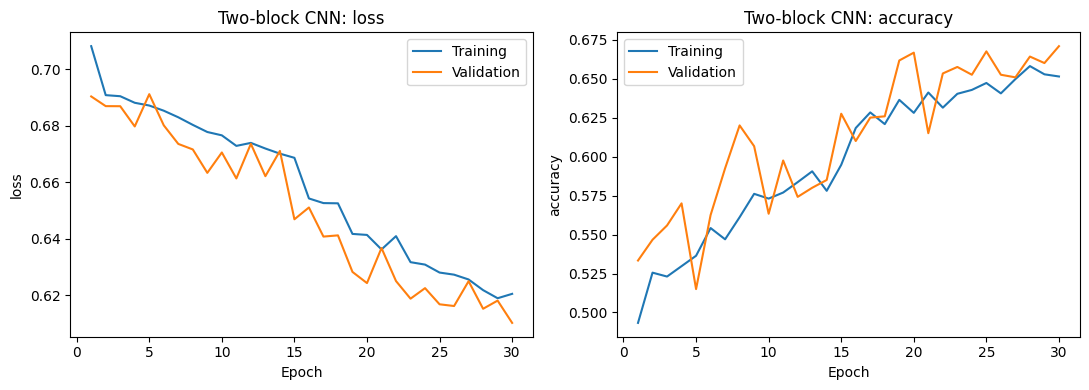

      model  parameters  epochs_run  seconds  batch_size  validation_loss  validation_accuracy  validation_balanced_accuracy  validation_auc  no_crack_recall  crack_recall  learned_both_classes
cnn_1_block        1649          30 2051.886          32            0.653                0.611                         0.611           0.673            0.688         0.533                  True
cnn_2_block        6673          30 2292.455          32            0.610                0.671                         0.671           0.736            0.703         0.638                  True


In [ ]:
# Reference implementation
tf.keras.utils.set_random_seed(SEED)
two_block_model = build_cnn(blocks=2)
two_block_model.summary()
two_history, two_summary = train_candidate(two_block_model)
plot_history(two_history, "Two-block CNN")
comparison = pd.DataFrame([one_summary, two_summary])
print(comparison.round(3).to_string(index=False))
models = {one_block_model.name: one_block_model, two_block_model.name: two_block_model}

### 7.1 Optional extension: Change batch size

Before opening the test results, you may retrain a **fresh** two-block CNN with batch size 64. Larger batches change how many weight updates occur per epoch; they are not guaranteed to improve accuracy or speed. Keep the data and epoch limit fixed, record the results, and add the candidate to the validation comparison.

The cell is skipped by default. Enable it only if time allows. Perform any further experiments on training and validation data before the final test report.

In [24]:
RUN_BATCH_EXPERIMENT = False
if RUN_BATCH_EXPERIMENT:
    tf.keras.utils.set_random_seed(SEED)
    batch_model = build_cnn(blocks=2)
    batch_history, batch_summary = train_candidate(batch_model, batch_size=64)
    batch_summary["model"] = "cnn_2_block_batch64"
    models[batch_summary["model"]] = batch_model
    comparison = pd.concat([comparison, pd.DataFrame([batch_summary])], ignore_index=True)
    print(comparison.round(3).to_string(index=False))

### 7.2 Choose using validation data and inspect thresholds

First exclude candidates that fail the validation learning check. Among the eligible models, choose **highest validation balanced accuracy** at threshold 0.50; use restored validation loss to break a tie. Training checkpoints still use validation loss. Balanced accuracy averages recall for the two classes. Keep the final classification threshold at **0.50** for the required report.

The validation-only table below illustrates thresholds of 0.30, 0.50, and 0.70. Lowering the threshold generally flags more images: recall can increase, while false alarms can also increase. Threshold selection in practice depends on the review workflow and should use validation data, never the test labels.

In [25]:
eligible = comparison[comparison["learned_both_classes"]].copy()
if eligible.empty:
    raise RuntimeError(
        "Neither CNN passed the validation learning check. Do not report a collapsed "
        "classifier as a successful demonstration. Inspect training curves, labels, and "
        "score distributions; revise training using validation data before opening the test set.")
winner = eligible.sort_values(["validation_balanced_accuracy", "validation_loss"],
                              ascending=[False, True]).iloc[0]["model"]
selected_model = models[winner]
print("Selected from validation results:", winner)
val_scores = selected_model.predict(val_ds, verbose=0).ravel()
threshold_rows = []
for threshold in (0.30, 0.50, 0.70):
    prediction = (val_scores >= threshold).astype(int)
    cm_val = confusion_matrix(val_df.label, prediction, labels=[0, 1])
    threshold_rows.append({"threshold": threshold,
                           "crack_precision": precision_score(val_df.label, prediction, zero_division=0),
                           "crack_recall": recall_score(val_df.label, prediction, zero_division=0),
                           "false_alarms": int(cm_val[0, 1]), "missed_cracks": int(cm_val[1, 0])})
print(pd.DataFrame(threshold_rows).round(3).to_string(index=False))
FINAL_THRESHOLD = 0.50

Selected from validation results: cnn_2_block
 threshold  crack_precision  crack_recall  false_alarms  missed_cracks
       0.3            0.534         0.967           507             20
       0.5            0.683         0.638           178            217
       0.7            0.828         0.208            26            475


**Your response:** Report which architecture was selected, explain the parameter-count difference, and describe what happened to missed cracks and false alarms when the validation threshold changed.

*Write here.*

### 7.3 Final held-out test report

Run the following cells after completing your model choices. Accuracy alone can hide class-specific problems. A **false negative** is a cracked patch predicted as uncracked; a **false positive** is an uncracked patch flagged as cracked. Crack recall is `TP / (TP + FN)`; crack precision is `TP / (TP + FP)`.

The balanced classroom subset does not reproduce the frequency of cracks in an actual inspection. Precision measured here may change substantially when cracks are rare in practice. Do not interpret these patch-level metrics as structure-level engineering performance.

Selected model: cnn_2_block | threshold: 0.50
Test loss: 0.598 | accuracy: 0.690
              precision    recall  f1-score   support

    No crack      0.692     0.685     0.688       600
       Crack      0.688     0.695     0.692       600

    accuracy                          0.690      1200
   macro avg      0.690     0.690     0.690      1200
weighted avg      0.690     0.690     0.690      1200

Test balanced accuracy: 0.69
Test ROC-AUC: 0.76
Correct no-crack: 411; false alarms: 189; missed cracks: 183; detected cracks: 417


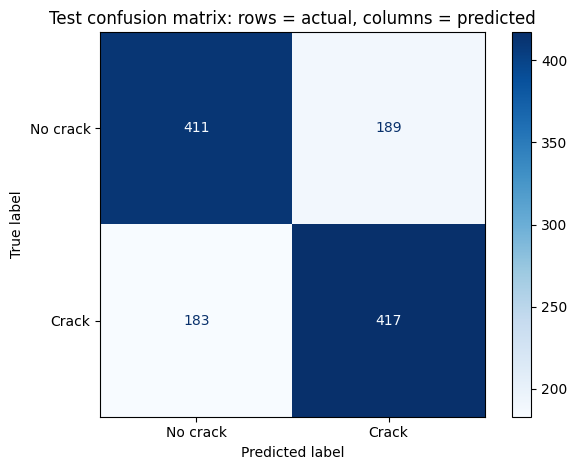

In [26]:
test_metrics = selected_model.evaluate(test_ds, return_dict=True, verbose=0)
test_scores = selected_model.predict(test_ds, verbose=0).ravel()
y_test = test_df.label.to_numpy(dtype=int)
test_predictions = (test_scores >= FINAL_THRESHOLD).astype(int)
print(f"Selected model: {winner} | threshold: {FINAL_THRESHOLD:.2f}")
print(f"Test loss: {test_metrics['loss']:.3f} | accuracy: {test_metrics['accuracy']:.3f}")
print(classification_report(y_test, test_predictions, labels=[0, 1],
                            target_names=["No crack", "Crack"], digits=3, zero_division=0))
print("Test balanced accuracy:", round(balanced_accuracy_score(y_test, test_predictions), 3))
print("Test ROC-AUC:", round(roc_auc_score(y_test, test_scores), 3))
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
if np.unique(test_predictions).size < 2:
    print("Learning check FAILED on test: predictions contain only one class.")
print(f"Correct no-crack: {tn}; false alarms: {fp}; missed cracks: {fn}; detected cracks: {tp}")
ConfusionMatrixDisplay(cm, display_labels=["No crack", "Crack"]).plot(
    cmap="Blues", values_format="d")
plt.title("Test confusion matrix: rows = actual, columns = predicted")
plt.tight_layout()
plt.show()
# Optional export: uncomment to save the trained model in your runtime.
# selected_model.save("module4_concrete_crack_cnn.keras")

### 7.4 Examine real classification errors

Review up to three missed cracks and three false alarms. If an error category is empty, the code reports that. Consider thin cracks, joints, shadows, holes, aggregate texture, or ambiguous labels as possible explanations, based on what you actually observe.

This is a final error analysis. If you redesign a model based on these test images, you need a new independent test set for an unbiased report.

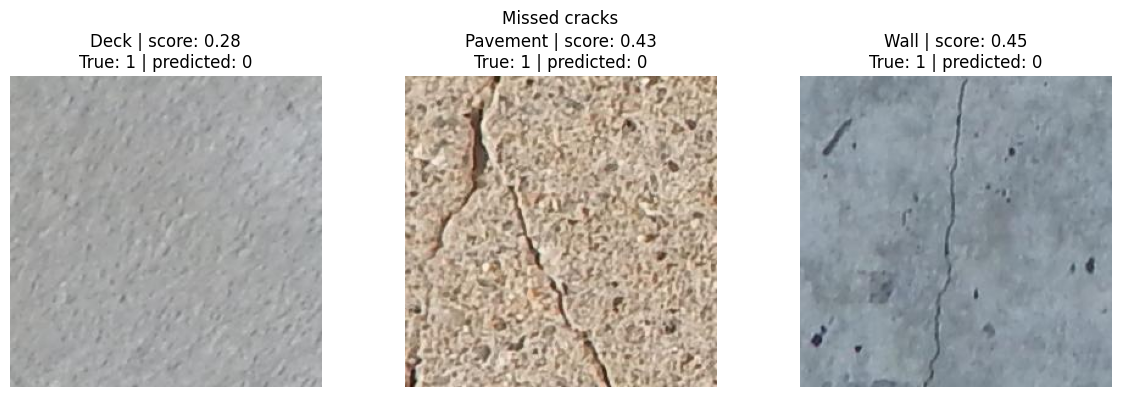

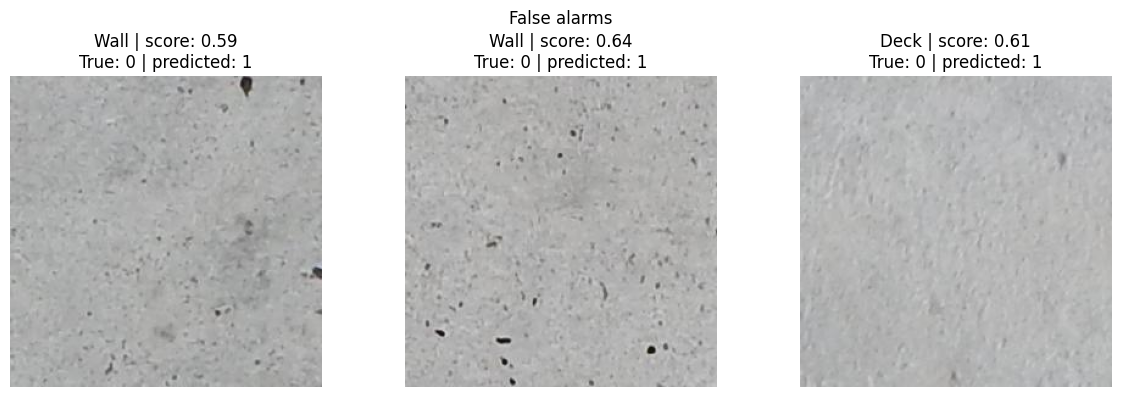

In [27]:
for title, mask in [("Missed cracks", (y_test == 1) & (test_predictions == 0)),
                    ("False alarms", (y_test == 0) & (test_predictions == 1))]:
    indices = np.flatnonzero(mask)[:3]
    if not len(indices):
        print(f"{title}: none in this test subset.")
        continue
    fig, axes = plt.subplots(1, len(indices), figsize=(4 * len(indices), 4), squeeze=False)
    for ax, idx in zip(axes.ravel(), indices):
        row = test_df.iloc[int(idx)]
        with Image.open(row.path) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(f"{row.surface} | score: {test_scores[idx]:.2f}\n"
                     f"True: {y_test[idx]} | predicted: {test_predictions[idx]}")
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## 8. Reflection and Extensions

1. How do local connections and shared filters differ from immediately flattening an image?
2. Why did the two-block model's parameter count differ from the one-block model's? How does global average pooling change the size of the classification head?
3. Did the second block improve validation performance? Use your measured results, rather than assuming deeper is better.
4. How many cracked test patches were missed? How would missed cracks and false alarms affect a human review queue?
5. What might be lost when a patch is resized to 128 × 128 or repeatedly pooled? Design a **validation-based** resolution experiment.
6. Why can random patch splits give optimistic results? Describe a split that holds out entire original photographs or structures.
7. What additional information would an engineer need to assess crack severity or plan maintenance? Consider physical scale, repeated inspections, material condition, and structural context.

### Lab submission

Submit your completed notebook with:

- Your work for Exercises 1–6 and written responses.
- Image counts and split counts, both model summaries, and training curves.
- The architecture comparison table, validation threshold table, and final test confusion matrix.
- A short paragraph describing one observed error and how the model could support construction or infrastructure inspection.

If no test errors occur, discuss a difficult validation patch instead and state that no errors were observed in this particular test subset. Report actual results; do not invent an accuracy value. Record the runtime and whether a GPU was used.

**Key idea:** A CNN can learn spatial patterns in construction imagery, but model depth, dataset design, and class-specific errors all matter. Use image classification to support evidence collection and review; crack presence alone does not establish structural condition.

### Sources and further reading

[1] Dorafshan, S., Thomas, R. J., and Maguire, M. (2018). “SDNET2018: An annotated image dataset for non-contact concrete crack detection using deep convolutional neural networks.” *Data in Brief*, 21, 1664–1668. [https://doi.org/10.1016/j.dib.2018.11.015](https://doi.org/10.1016/j.dib.2018.11.015). [Original dataset record](https://doi.org/10.15142/T3TD19).

[2] [SDNET2018 distribution on Kaggle](https://www.kaggle.com/datasets/aniruddhsharma/structural-defects-network-concrete-crack-images/data).

[3] [KaggleHub documentation](https://github.com/Kaggle/kagglehub).

[4] [Keras Conv2D documentation](https://keras.io/api/layers/convolution_layers/convolution2d/) and [MaxPooling2D documentation](https://keras.io/api/layers/pooling_layers/max_pooling2d/).

[5] [Keras EarlyStopping documentation](https://keras.io/api/callbacks/early_stopping/).

**Course attribution:** The supplied Module 3 notebook guides the teaching format. The supplied IBM course notebook provides background on the general one-block/two-block CNN comparison. The explanatory prose, exercises, SDNET workflow, and implementations in this Module 4 lab are newly written; IBM text, branding, and MNIST lab cells are not reproduced. Dataset credit remains with its creators.

[6] [Keras LeakyReLU](https://keras.io/api/layers/activation_layers/leaky_relu/), [LayerNormalization](https://keras.io/api/layers/normalization_layers/layer_normalization/), and [ReduceLROnPlateau](https://keras.io/api/callbacks/reduce_lr_on_plateau/).
